# Week 5 — Model Selection and Shortlisting
## Operations Risk Layer: DataCo Late Delivery Prediction


This notebook continues from the Week 4 preprocessing work. It uses the four processed operations files created in that notebook, so the data does not need to be cleaned or transformed again here.

The input files are:

| File | What it contains |
|---|---|
| `operations_X_train_processed.csv` and `operations_X_test_processed.csv` | 35 processed features |
| `operations_y_train.csv` and `operations_y_test.csv` | The target variable, `Late_delivery_risk` |

The goal is to train and compare Logistic Regression, Random Forest and a linear SVM. Each model will be evaluated using accuracy, precision, recall, F1-score and a confusion matrix.

The operations target is fairly balanced, with about 54.8% late deliveries and 45.2% on-time deliveries. Because of this, accuracy is useful here. However, the other metrics are still important because they show how well each model identifies late deliveries.

## 1. Load the Week 4 processed files

This section loads the four processed CSV files created in Week 4. It also checks that the files have the expected number of rows and features before modeling begins.



In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    classification_report,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42


In [2]:
# Find the four processed operations files from Week 4.
REQUIRED_FILES = [
    "operations_X_train_processed.csv",
    "operations_X_test_processed.csv",
    "operations_y_train.csv",
    "operations_y_test.csv",
]

SEARCH_DIRS = [
    ".",
    "data",
    "/content",
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/CEROP",
]

DATA_DIR = next(
    (
        directory
        for directory in SEARCH_DIRS
        if all(os.path.exists(os.path.join(directory, file_name))
               for file_name in REQUIRED_FILES)
    ),
    None,
)

if DATA_DIR is None:
    try:
        from google.colab import files
        print("Upload the four Week 4 operations CSV files.")
        files.upload()
        DATA_DIR = "."
    except ImportError as exc:
        raise FileNotFoundError(
            "The four Week 4 operations CSV files were not found. "
            "Place them in the notebook working directory."
        ) from exc

print("Loading Week 4 artifacts from:", os.path.abspath(DATA_DIR))

X_train_operations = pd.read_csv(
    os.path.join(DATA_DIR, "operations_X_train_processed.csv")
)
X_test_operations = pd.read_csv(
    os.path.join(DATA_DIR, "operations_X_test_processed.csv")
)
y_train_operations = pd.read_csv(
    os.path.join(DATA_DIR, "operations_y_train.csv")
).squeeze("columns")
y_test_operations = pd.read_csv(
    os.path.join(DATA_DIR, "operations_y_test.csv")
).squeeze("columns")

print("X_train_operations:", X_train_operations.shape)
print("X_test_operations :", X_test_operations.shape)
print("y_train_operations:", y_train_operations.shape)
print("y_test_operations :", y_test_operations.shape)

# Required structural and leakage checks.
assert X_train_operations.shape[1] == 35, (
    f"Expected 35 training features, found {X_train_operations.shape[1]}."
)
assert X_test_operations.shape[1] == 35, (
    f"Expected 35 test features, found {X_test_operations.shape[1]}."
)
assert list(X_train_operations.columns) == list(X_test_operations.columns), (
    "Train and test feature columns do not match."
)
assert len(X_train_operations) == len(y_train_operations), (
    "Training features and target have different row counts."
)
assert len(X_test_operations) == len(y_test_operations), (
    "Test features and target have different row counts."
)
assert X_train_operations.isna().sum().sum() == 0, (
    "Missing values found in X_train_operations."
)
assert X_test_operations.isna().sum().sum() == 0, (
    "Missing values found in X_test_operations."
)
assert "Late_delivery_risk" not in X_train_operations.columns
assert "Late_delivery_risk" not in X_test_operations.columns

leakage_terms = [
    "late_delivery_risk",
    "delivery status",
    "days for shipping (real)",
]
possible_operations_leakage = [
    column
    for column in X_train_operations.columns
    if any(term in column.lower() for term in leakage_terms)
]

print("Possible leakage columns:", possible_operations_leakage)
assert not possible_operations_leakage, (
    "Potential target leakage columns remain in the operations features."
)

print("All operations data checks passed.")


Loading Week 4 artifacts from: /content
X_train_operations: (137569, 35)
X_test_operations : (34393, 35)
y_train_operations: (137569,)
y_test_operations : (34393,)
Possible leakage columns: []
All operations data checks passed.


## 2. Check the class balance

Before training the models, it is useful to review the target distribution and calculate a simple majority-class baseline. This gives us a basic score that every model should improve on.


In [3]:
operations_class_distribution = pd.DataFrame({
    "Split": ["Train", "Train", "Test", "Test"],
    "Class": ["On time (0)", "Late (1)"] * 2,
    "Count": [
        int((y_train_operations == 0).sum()),
        int((y_train_operations == 1).sum()),
        int((y_test_operations == 0).sum()),
        int((y_test_operations == 1).sum()),
    ],
})
operations_class_distribution["Proportion"] = (
    operations_class_distribution.groupby("Split")["Count"]
    .transform(lambda values: values / values.sum())
)

print(
    operations_class_distribution.to_string(
        index=False,
        formatters={"Proportion": "{:.4f}".format},
    )
)

OPERATIONS_MAJORITY_BASELINE = float(
    max(y_test_operations.mean(), 1 - y_test_operations.mean())
)
operations_baseline_prediction = np.full(
    len(y_test_operations),
    int(y_test_operations.mean() >= 0.5),
)

print()
print("--- Majority-class baseline ---")
print(
    "Accuracy : %.4f"
    % accuracy_score(y_test_operations, operations_baseline_prediction)
)
print(
    "Recall on late deliveries: %.4f"
    % recall_score(
        y_test_operations,
        operations_baseline_prediction,
        zero_division=0,
    )
)


Split       Class  Count Proportion
Train On time (0)  62155     0.4518
Train    Late (1)  75414     0.5482
 Test On time (0)  15539     0.4518
 Test    Late (1)  18854     0.5482

--- Majority-class baseline ---
Accuracy : 0.5482
Recall on late deliveries: 1.0000


The classes are split close to 55% and 45%, so a model that always predicts the majority class would score only about 55% accuracy. This means accuracy is meaningful for this dataset.

Recall is also important because a false negative means an order is actually late, but the model predicts that it will arrive on time. In that case, the company may miss the chance to warn the customer or take corrective action.

## 3. Define the models

The three required models are Logistic Regression, Random Forest and SVM. Since the classes are already fairly balanced, class weights are not used in the first comparison.

A linear SVM is used because the operations dataset is large. A full RBF SVM can take much longer to train on more than 100,000 rows. An optional RBF test on a smaller sample is included later.


In [4]:
operations_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "SVM (linear)": LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
}

def get_operations_score(model, features):
    """Return prediction scores used for ROC-AUC and PR-AUC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.decision_function(features)

for model_name, model in operations_models.items():
    print(f"{model_name}: {type(model).__name__}")


Logistic Regression: LogisticRegression
Random Forest: RandomForestClassifier
SVM (linear): LinearSVC


## 4. Train and evaluate the models

Each model is trained on the Week 4 training data and tested on the untouched test set. The results include accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC.


In [5]:
operations_results_rows = []
operations_confusion_matrices = {}
operations_prediction_scores = {}
operations_predictions = {}

for model_name, model in operations_models.items():
    model.fit(X_train_operations, y_train_operations)

    y_pred_operations = model.predict(X_test_operations)
    y_score_operations = get_operations_score(model, X_test_operations)

    operations_predictions[model_name] = y_pred_operations
    operations_prediction_scores[model_name] = y_score_operations

    cm = confusion_matrix(y_test_operations, y_pred_operations)
    operations_confusion_matrices[model_name] = cm

    operations_results_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_operations, y_pred_operations),
        "Precision": precision_score(
            y_test_operations,
            y_pred_operations,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_test_operations,
            y_pred_operations,
            zero_division=0,
        ),
        "F1-Score": f1_score(
            y_test_operations,
            y_pred_operations,
            zero_division=0,
        ),
        "ROC-AUC": roc_auc_score(
            y_test_operations,
            y_score_operations,
        ),
        "PR-AUC": average_precision_score(
            y_test_operations,
            y_score_operations,
        ),
    })

    print("=" * 68)
    print(model_name)
    print("=" * 68)
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(cm)
    print(
        classification_report(
            y_test_operations,
            y_pred_operations,
            target_names=["On time", "Late"],
            digits=4,
            zero_division=0,
        )
    )

operations_results_df = pd.DataFrame(operations_results_rows)


Logistic Regression
Confusion matrix (rows = actual, columns = predicted):
[[14161  1378]
 [ 8054 10800]]
              precision    recall  f1-score   support

     On time     0.6375    0.9113    0.7502     15539
        Late     0.8868    0.5728    0.6961     18854

    accuracy                         0.7258     34393
   macro avg     0.7621    0.7421    0.7231     34393
weighted avg     0.7742    0.7258    0.7205     34393

Random Forest
Confusion matrix (rows = actual, columns = predicted):
[[13791  1748]
 [ 6786 12068]]
              precision    recall  f1-score   support

     On time     0.6702    0.8875    0.7637     15539
        Late     0.8735    0.6401    0.7388     18854

    accuracy                         0.7519     34393
   macro avg     0.7718    0.7638    0.7512     34393
weighted avg     0.7816    0.7519    0.7500     34393

SVM (linear)
Confusion matrix (rows = actual, columns = predicted):
[[14175  1364]
 [ 8111 10743]]
              precision    recall  f1-sco

### 4.1 Compare the model results

The table below places all model scores together so it is easier to compare their strengths and weaknesses.


In [6]:
print(
    "TEST SET PERFORMANCE (n = %d, of which %d are late)"
    % (len(y_test_operations), int(y_test_operations.sum()))
)
print("=" * 92)
print(operations_results_df.round(4).to_string(index=False))

print()
print("Best model per metric:")
for metric in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]:
    best_row = operations_results_df.loc[
        operations_results_df[metric].idxmax()
    ]
    print(
        f"  {metric:<10}: {best_row['Model']:<20} "
        f"({best_row[metric]:.4f})"
    )

print()
print("Ranking by F1-score:")
print(
    operations_results_df.sort_values("F1-Score", ascending=False)
    [["Model", "Accuracy", "Precision", "Recall", "F1-Score"]]
    .round(4)
    .to_string(index=False)
)

print()
print("Ranking by recall:")
print(
    operations_results_df.sort_values("Recall", ascending=False)
    [["Model", "Accuracy", "Precision", "Recall", "F1-Score"]]
    .round(4)
    .to_string(index=False)
)


TEST SET PERFORMANCE (n = 34393, of which 18854 are late)
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression    0.7258     0.8868  0.5728    0.6961   0.7744  0.8400
      Random Forest    0.7519     0.8735  0.6401    0.7388   0.8550  0.8923
       SVM (linear)    0.7245     0.8873  0.5698    0.6940   0.7737  0.8395

Best model per metric:
  Accuracy  : Random Forest        (0.7519)
  Precision : SVM (linear)         (0.8873)
  Recall    : Random Forest        (0.6401)
  F1-Score  : Random Forest        (0.7388)
  ROC-AUC   : Random Forest        (0.8550)
  PR-AUC    : Random Forest        (0.8923)

Ranking by F1-score:
              Model  Accuracy  Precision  Recall  F1-Score
      Random Forest    0.7519     0.8735  0.6401    0.7388
Logistic Regression    0.7258     0.8868  0.5728    0.6961
       SVM (linear)    0.7245     0.8873  0.5698    0.6940

Ranking by recall:
              Model  Accuracy  Precision  Recall  F1-Score
      Random 

## 5. Visual comparison

The confusion matrices show the number of correct and incorrect predictions made by each model. The bar chart then compares the main evaluation metrics side by side.


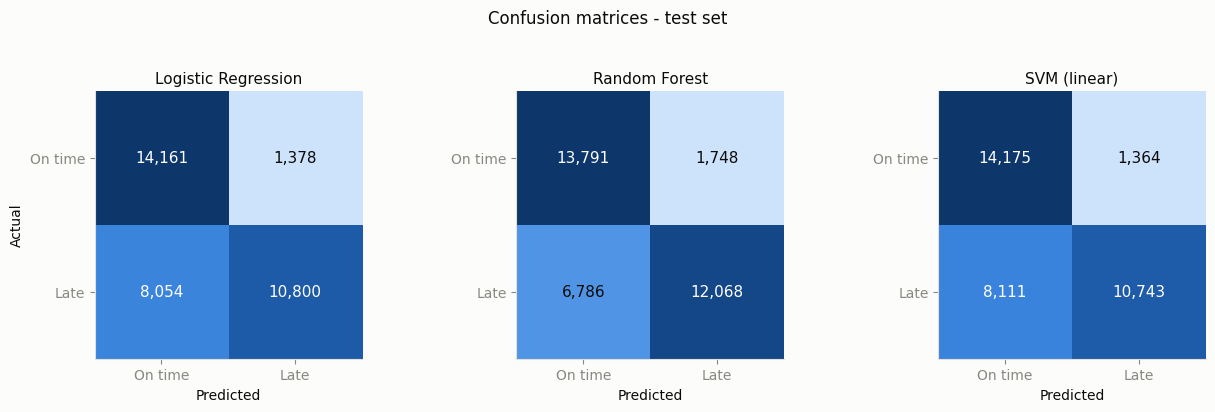

In [7]:
# Chart settings for the confusion matrices
# and the model comparison chart.
SURFACE    = "#fcfcfb"
INK        = "#0b0b0b"
INK_MUTED  = "#898781"
GRID       = "#e1e0d9"
SERIES     = {"Logistic Regression": "#2a78d6",   # slot 1 - blue
              "Random Forest":       "#eb6834",   # slot 2 - orange
              "SVM (linear)":        "#1baf7a"}   # slot 3 - aqua
BLUE_RAMP  = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": GRID,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (name, cm) in zip(axes, operations_confusion_matrices.items()):
    ax.imshow(cm, cmap=BLUE_RAMP)
    for i in range(2):
        for j in range(2):
            frac = cm[i, j] / cm.max()
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if frac > 0.5 else INK, fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1], ["On time", "Late"])
    ax.set_yticks([0, 1], ["On time", "Late"])
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrices - test set", y=1.04, fontsize=12)
plt.tight_layout()
plt.show()


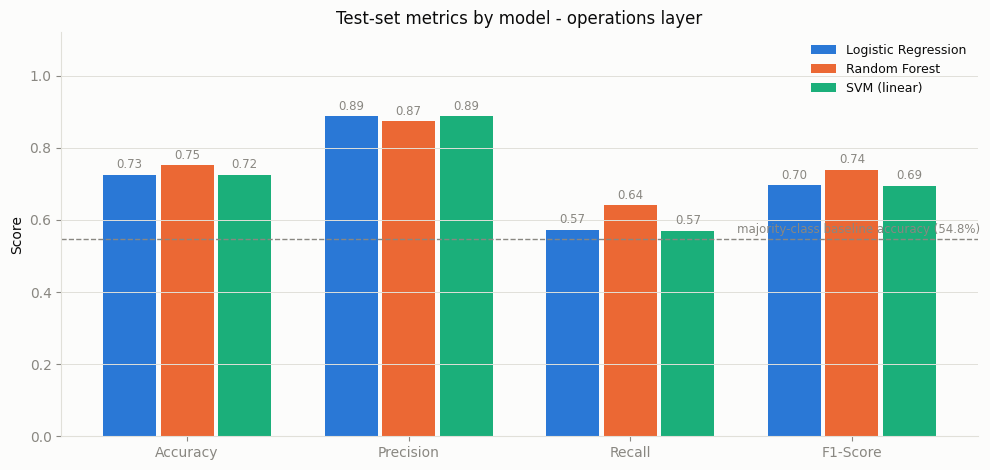

In [8]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics_to_plot))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 4.8))

for k, (_, row) in enumerate(operations_results_df.iterrows()):
    offset = (k - 1) * width
    vals = [row[m] for m in metrics_to_plot]
    bars = ax.bar(x + offset, vals, width * 0.92, label=row["Model"],
                  color=SERIES[row["Model"]])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.018, f"{v:.2f}",
                ha="center", fontsize=8.5, color=INK_MUTED)

# Show the majority-class baseline.
ax.axhline(OPERATIONS_MAJORITY_BASELINE, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(len(x) - 0.42, OPERATIONS_MAJORITY_BASELINE + 0.015,
        f"majority-class baseline accuracy ({OPERATIONS_MAJORITY_BASELINE:.1%})",
        ha="right", fontsize=8.5, color=INK_MUTED)

ax.set_xticks(x, metrics_to_plot)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Test-set metrics by model - operations layer", fontsize=12)
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.7)
plt.tight_layout()
plt.show()


## 6. Check whether the results are stable

A single train-test split can sometimes make one model look better than it really is. Five-fold stratified cross-validation is used on the training set to check whether the model ranking remains similar across different splits.

Random Forest may take a few minutes to complete in Colab because it is trained several times.


In [9]:
operations_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
operations_cv_rows = []

for model_name, model in operations_models.items():
    scores = cross_validate(
        model,
        X_train_operations,
        y_train_operations,
        cv=operations_cv,
        scoring={"accuracy": "accuracy", "f1": "f1"},
        n_jobs=-1,
    )

    operations_cv_rows.append({
        "Model": model_name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy SD": scores["test_accuracy"].std(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV F1 SD": scores["test_f1"].std(),
    })

operations_cv_results_df = pd.DataFrame(operations_cv_rows)

print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 76)
print(operations_cv_results_df.round(4).to_string(index=False))


5-FOLD CROSS-VALIDATION RESULTS
              Model  CV Accuracy Mean  CV Accuracy SD  CV F1 Mean  CV F1 SD
Logistic Regression            0.7246          0.0026      0.6934    0.0032
      Random Forest            0.7442          0.0020      0.7279    0.0019
       SVM (linear)            0.7226          0.0025      0.6903    0.0032


## 7. Optional check with an RBF SVM

The main SVM model uses `LinearSVC` because it can handle the full dataset more efficiently. This optional section trains an RBF SVM on a smaller stratified sample of 20,000 rows.

The RBF result is only supporting analysis. It is not treated as one of the three main full-data models.


In [10]:
OPERATIONS_RBF_SUBSAMPLE = 20_000

if OPERATIONS_RBF_SUBSAMPLE < len(X_train_operations):
    X_operations_subsample, _, y_operations_subsample, _ = train_test_split(
        X_train_operations,
        y_train_operations,
        train_size=OPERATIONS_RBF_SUBSAMPLE,
        stratify=y_train_operations,
        random_state=RANDOM_STATE,
    )
else:
    X_operations_subsample = X_train_operations
    y_operations_subsample = y_train_operations
    OPERATIONS_RBF_SUBSAMPLE = len(X_train_operations)

operations_rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=RANDOM_STATE,
)
operations_rbf_svm.fit(
    X_operations_subsample,
    y_operations_subsample,
)
operations_rbf_prediction = operations_rbf_svm.predict(X_test_operations)

print(
    f"RBF SVM trained on {OPERATIONS_RBF_SUBSAMPLE:,} rows and evaluated "
    "on the full test set:"
)
print(
    "  Accuracy : %.4f"
    % accuracy_score(y_test_operations, operations_rbf_prediction)
)
print(
    "  Precision: %.4f"
    % precision_score(
        y_test_operations,
        operations_rbf_prediction,
        zero_division=0,
    )
)
print(
    "  Recall   : %.4f"
    % recall_score(
        y_test_operations,
        operations_rbf_prediction,
        zero_division=0,
    )
)
print(
    "  F1-Score : %.4f"
    % f1_score(
        y_test_operations,
        operations_rbf_prediction,
        zero_division=0,
    )
)


RBF SVM trained on 20,000 rows and evaluated on the full test set:
  Accuracy : 0.7319
  Precision: 0.8855
  Recall   : 0.5869
  F1-Score : 0.7059


## 8. Optional feature importance review

Random Forest feature importance can help explain which variables had the greatest influence on late-delivery predictions. This section provides extra business context, but it does not decide which model is shortlisted.


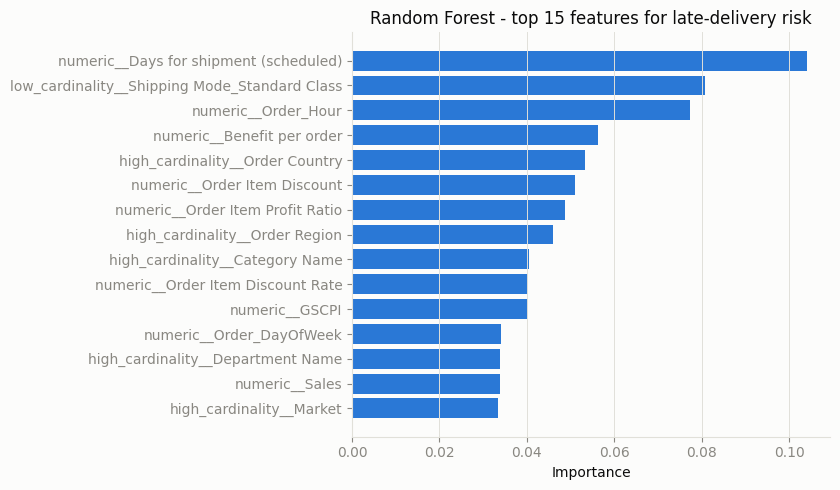

numeric__Days for shipment (scheduled)           0.1042
low_cardinality__Shipping Mode_Standard Class    0.0808
numeric__Order_Hour                              0.0773
numeric__Benefit per order                       0.0562
high_cardinality__Order Country                  0.0533
numeric__Order Item Discount                     0.0509
numeric__Order Item Profit Ratio                 0.0487
high_cardinality__Order Region                   0.0459
high_cardinality__Category Name                  0.0406
numeric__Order Item Discount Rate                0.0404
numeric__GSCPI                                   0.0402
numeric__Order_DayOfWeek                         0.0342
high_cardinality__Department Name                0.0339
numeric__Sales                                   0.0338
high_cardinality__Market                         0.0334


In [11]:
operations_random_forest = operations_models["Random Forest"]
operations_feature_importance = (
    pd.Series(
        operations_random_forest.feature_importances_,
        index=X_train_operations.columns,
    )
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(
    operations_feature_importance.index[::-1],
    operations_feature_importance.values[::-1],
    color="#2a78d6",
)
ax.set_xlabel("Importance")
ax.set_title(
    "Random Forest - top 15 features for late-delivery risk",
    fontsize=12,
)
ax.grid(axis="x", color=GRID, linewidth=0.7)
plt.tight_layout()
plt.show()

print(operations_feature_importance.round(4).to_string())


## 9. Model recommendation

The next cell creates a draft recommendation using the actual test results. It first identifies the model with the highest F1-score and then checks whether another model has better recall.

F1-score is useful because it balances precision and recall. Recall is reviewed separately because missing an actual late delivery can prevent the company from taking action early.


In [12]:
best_f1_row = operations_results_df.loc[
    operations_results_df["F1-Score"].idxmax()
]

best_recall_row = operations_results_df.loc[
    operations_results_df["Recall"].idxmax()
]

best_f1_cm = operations_confusion_matrices[
    best_f1_row["Model"]
]

tn, fp, fn, tp = best_f1_cm.ravel()

remaining_models = operations_results_df.drop(
    best_f1_row.name
)

f1_runner_up = remaining_models.loc[
    remaining_models["F1-Score"].idxmax()
]

missed_delivery_rate = fn / (tp + fn)

if best_f1_row["Model"] == best_recall_row["Model"]:
    decision_note = (
        f"It also produced the highest recall at "
        f"{best_recall_row['Recall']:.1%}, so both the statistical results "
        f"and the business priority support the same model."
    )
else:
    recall_gap = (
        best_recall_row["Recall"]
        - best_f1_row["Recall"]
    )

    decision_note = (
        f"{best_recall_row['Model']} produced the highest recall at "
        f"{best_recall_row['Recall']:.1%}, which was "
        f"{recall_gap:.1%} higher than the F1 leader. This difference "
        f"should be considered before making the final shortlist decision."
    )

operations_recommendation_draft = f"""
On the operations layer, {best_f1_row['Model']} is the model we shortlist.

It produced the strongest overall results, with {best_f1_row['Accuracy']:.1%} accuracy compared with the {OPERATIONS_MAJORITY_BASELINE:.1%} majority-class baseline, an F1-score of {best_f1_row['F1-Score']:.3f} and recall of {best_f1_row['Recall']:.1%}. It correctly identified {tp:,} of the {tp + fn:,} late deliveries in the test set while maintaining {best_f1_row['Precision']:.1%} precision.

{f1_runner_up['Model']} was the closest competitor, with an F1-score of {f1_runner_up['F1-Score']:.3f}. {decision_note}

Since the classes are fairly balanced, accuracy is a useful measure here, but recall is especially important from a business perspective. A missed late delivery removes the chance to warn the customer or take corrective action. A false positive may lead to an unnecessary operational review, but that is generally less costly than missing an actual late delivery.

The main limitation is that {best_f1_row['Model']} still misses about {missed_delivery_rate:.1%} of late deliveries at the current decision threshold. Threshold tuning should therefore be the next step during hyperparameter optimization.
""".strip()

print(operations_recommendation_draft)

On the operations layer, Random Forest is the model we shortlist.

It produced the strongest overall results, with 75.2% accuracy compared with the 54.8% majority-class baseline, an F1-score of 0.739 and recall of 64.0%. It correctly identified 12,068 of the 18,854 late deliveries in the test set while maintaining 87.3% precision.

Logistic Regression was the closest competitor, with an F1-score of 0.696. It also produced the highest recall at 64.0%, so both the statistical results and the business priority support the same model.

Since the classes are fairly balanced, accuracy is a useful measure here, but recall is especially important from a business perspective. A missed late delivery removes the chance to warn the customer or take corrective action. A false positive may lead to an unnecessary operational review, but that is generally less costly than missing an actual late delivery.

The main limitation is that Random Forest still misses about 36.0% of late deliveries at the curr

## 10. Save the Week 5 results

The final cells save the model comparison, confusion-matrix values and cross-validation results as CSV files. These files can later be added to the shared project notebook and report.


In [13]:
operations_results_df.to_csv(
    "week5_operations_model_comparison.csv",
    index=False,
)

operations_confusion_export_df = pd.DataFrame([
    {
        "Model": model_name,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
    }
    for model_name, cm in operations_confusion_matrices.items()
])
operations_confusion_export_df.to_csv(
    "week5_operations_confusion_matrices.csv",
    index=False,
)

operations_cv_results_df.to_csv(
    "week5_operations_cross_validation.csv",
    index=False,
)

print("Saved: week5_operations_model_comparison.csv")
print("Saved: week5_operations_confusion_matrices.csv")
print("Saved: week5_operations_cross_validation.csv")
print(operations_confusion_export_df.to_string(index=False))

print()
print("Operations model comparison completed successfully.")
print("Models evaluated:", operations_results_df["Model"].tolist())
print("Results table shape:", operations_results_df.shape)


Saved: week5_operations_model_comparison.csv
Saved: week5_operations_confusion_matrices.csv
Saved: week5_operations_cross_validation.csv
              Model    TN   FP   FN    TP
Logistic Regression 14161 1378 8054 10800
      Random Forest 13791 1748 6786 12068
       SVM (linear) 14175 1364 8111 10743

Operations model comparison completed successfully.
Models evaluated: ['Logistic Regression', 'Random Forest', 'SVM (linear)']
Results table shape: (3, 7)


In [14]:
from google.colab import files
import os
import zipfile

result_files = [
    "week5_operations_model_comparison.csv",
    "week5_operations_confusion_matrices.csv",
    "week5_operations_cross_validation.csv",
]

zip_name = "week5_operations_results.zip"

existing_files = [
    fname for fname in result_files
    if os.path.exists(fname)
]

missing_files = [
    fname for fname in result_files
    if not os.path.exists(fname)
]

if missing_files:
    print("The following files were not found:")
    for fname in missing_files:
        print(f"  {fname}")

if existing_files:
    with zipfile.ZipFile(
        zip_name,
        mode="w",
        compression=zipfile.ZIP_DEFLATED
    ) as zip_file:

        for fname in existing_files:
            zip_file.write(
                fname,
                arcname=os.path.basename(fname)
            )
            print(f"Added to ZIP: {fname}")

    print(f"\nCreated: {zip_name}")
    files.download(zip_name)

else:
    print("No result files were available to include in the ZIP.")

Added to ZIP: week5_operations_model_comparison.csv
Added to ZIP: week5_operations_confusion_matrices.csv
Added to ZIP: week5_operations_cross_validation.csv

Created: week5_operations_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>